In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [27]:
df = pd.read_excel("clust_2003.xlsx")
df = df[~df["regions"].isin(["Республика Ингушетия", "Ямало-Ненецкий автономный округ", "Чукотский автономный округ"])].set_index("regions")

In [37]:
df.shape

(79, 4)

In [28]:
df_with_clusters_not_scaled = df.copy()

In [29]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

for i in df.columns:
    df[i] = df_scaled[:, 0] 

df.head()

,x1,x2,x3,x4
regions,,,,
Белгородская область,-0.737943,-0.737943,-0.737943,-0.737943
Брянская область,-0.655173,-0.655173,-0.655173,-0.655173
Владимирская область,0.558783,0.558783,0.558783,0.558783
Воронежская область,-1.069022,-1.069022,-1.069022,-1.069022
Ивановская область,-0.379274,-0.379274,-0.379274,-0.379274


In [30]:
df_with_clusters_scaled = df.copy()

In [31]:
agg_cluster = AgglomerativeClustering(n_clusters=6, linkage='ward')
df_with_clusters_not_scaled["clusters"] = agg_cluster.fit_predict(df)
df_with_clusters_scaled["clusters"] = agg_cluster.fit_predict(df)

In [32]:
df_with_clusters_not_scaled.groupby(by = ["clusters"]).count() 

,x1,x2,x3,x4
clusters,,,,
0,6,6,6,6
1,23,23,23,23
2,6,6,6,6
3,10,10,10,10
4,17,17,17,17
5,17,17,17,17


In [33]:
df_with_clusters_not_scaled[df_with_clusters_not_scaled['clusters'] == 5]

,x1,x2,x3,x4,clusters
regions,,,,,
Владимирская область,66.6,10.2,6.164,31.5,5
Калужская область,66.5,6.1,9.016,33.2,5
Республика Карелия,66.7,8.2,13.531,19.0,5
Вологодская область,65.4,4.9,14.042,20.0,5
Калининградская область,66.4,7.5,15.617,35.1,5
Ленинградская область,66.1,8.6,26.468,38.1,5
Новгородская область,66.8,4.9,13.279,28.7,5
Республика Татарстан,65.4,6.6,17.585,19.8,5
Удмуртская Республика,66.8,6.6,8.422,31.1,5


<Axes: >

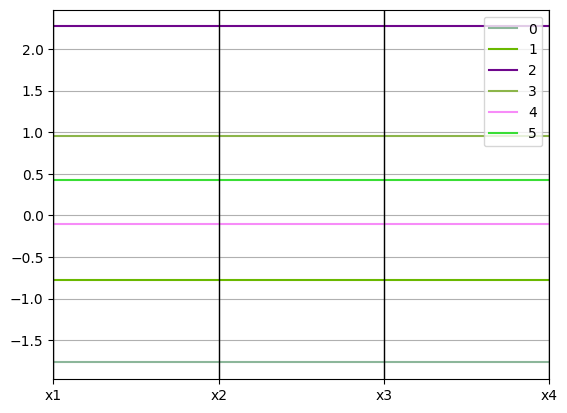

In [34]:
df_with_means = df_with_clusters_scaled.groupby(by = ["clusters"]).mean().reset_index()
pd.plotting.parallel_coordinates(df_with_means, "clusters")

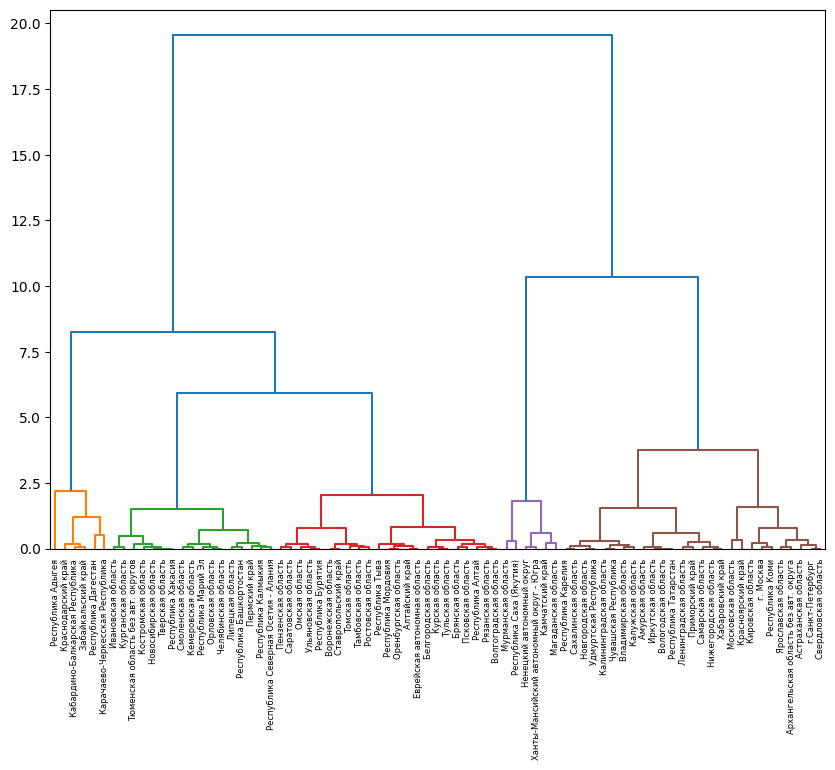

In [39]:
Z = linkage(df, method='ward', metric='euclidean')

fig = plt.figure(figsize=(10, 7))
dn = dendrogram(Z, color_threshold=5, orientation="top", labels = df.index)
plt.show()

In [36]:
df_with_clusters_not_scaled.to_excel("clusters_2003.xlsx")